# 14 · Intel Berkeley Research Lab – real sensor faults

**Utility for the City Brain: high** · Domain: sensor faults · Incident types: all (fake readings)

> Readings from 54 cheap wireless sensors over 5 weeks. When batteries die, sensors report up to 385 °C: a 'fire' with no fire. Real fault shapes for testing and for the Guardian.

| | |
|---|---|
| **Source** | MIT CSAIL / Intel Research Berkeley, 2004 (`db.csail.mit.edu/labdata`) |
| **Licence** | Open; acknowledge Intel Research Berkeley |
| **In this repo** | Sample: all readings of 8 motes (`data/sensor-faults/intel-lab/intel_8motes.txt.gz`) + positions |
| **Get it** | http://db.csail.mit.edu/labdata/data.txt.gz (2.3 M readings) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

Space-separated, no header: `date time epoch moteid temperature(°C) humidity(%) light(lux) voltage(V)`, about every 31 s. `mote_locs.txt` = mote id, x, y (metres in the lab). About 4 % of lines are incomplete.

In [2]:
rows = [l.split() for l in gzip.open(path('sensor-faults/intel-lab/intel_8motes.txt.gz'), 'rt')]
x = pd.DataFrame([r for r in rows if len(r) == 8], columns=['date', 'time', 'epoch', 'mote', 'temp', 'hum', 'light', 'volt'])
x[['epoch', 'mote']] = x[['epoch', 'mote']].astype(int); x[['temp', 'hum', 'light', 'volt']] = x[['temp', 'hum', 'light', 'volt']].astype(float)
x['ts'] = pd.to_datetime(x.date + ' ' + x.time, format='mixed'); x = x.sort_values(['mote', 'ts'])
print(f"{len(x):,} readings, motes {sorted(x.mote.unique())}, {x.ts.min():%d %b} to {x.ts.max():%d %b %Y}"); x.head()

379,614 readings, motes [np.int64(1), np.int64(2), np.int64(7), np.int64(13), np.int64(22), np.int64(31), np.int64(40), np.int64(49)], 28 Feb to 01 Apr 2004


,date,time,epoch,mote,temp,hum,light,volt,ts
1,2004-02-28,00:59:16.02785,3,1,19.9884,37.0933,45.08,2.69964,2004-02-28 00:59:16.027850
2,2004-02-28,01:03:16.33393,11,1,19.3024,38.4629,45.08,2.68742,2004-02-28 01:03:16.333930
3,2004-02-28,01:06:16.013453,17,1,19.1652,38.8039,45.08,2.68742,2004-02-28 01:06:16.013453
4,2004-02-28,01:06:46.778088,18,1,19.1750,38.8379,45.08,2.69964,2004-02-28 01:06:46.778088
5,2004-02-28,01:08:45.992524,22,1,19.1456,38.9401,45.08,2.68742,2004-02-28 01:08:45.992524


## 2. Dying batteries produce fake extreme readings

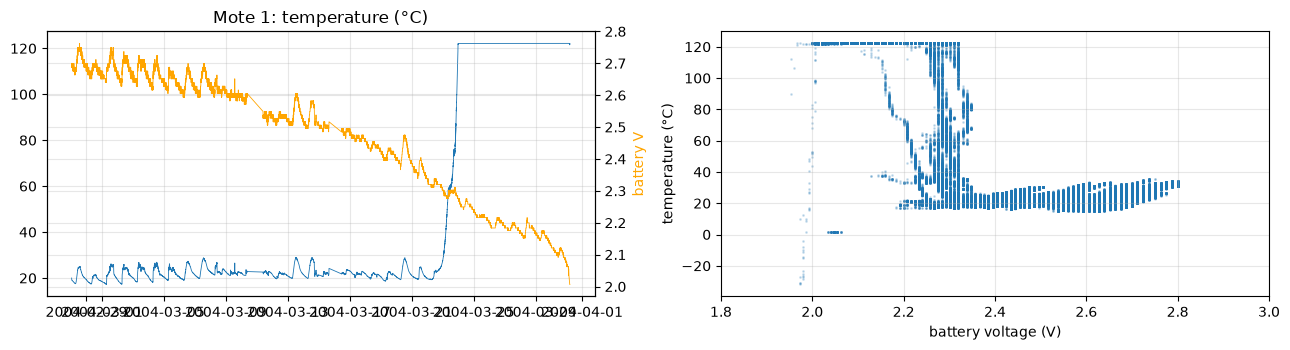

Readings above 50 °C: 15.8 % (max 122 °C)
... of which at battery < 2.4 V: 100.0 %; readings > 50 °C with battery >= 2.4 V: 0


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
m = x[x.mote == x.mote.unique()[0]]
ax[0].plot(m.ts, m.temp, lw=.6); ax[0].set_title(f'Mote {m.mote.iloc[0]}: temperature (°C)')
ax2 = ax[0].twinx(); ax2.plot(m.ts, m.volt, c='orange', lw=.6); ax2.set_ylabel('battery V', color='orange')
ax[1].scatter(x.volt, x.temp, s=1, alpha=.2); ax[1].set_xlabel('battery voltage (V)'); ax[1].set_ylabel('temperature (°C)'); ax[1].set_xlim(1.8, 3)
plt.tight_layout(); plt.show()
hot = x.temp > 50
print(f"Readings above 50 °C: {hot.mean() * 100:.1f} % (max {x.temp.max():.0f} °C)")
print(f"... of which at battery < 2.4 V: {(x[hot].volt < 2.4).mean() * 100:.1f} %; readings > 50 °C with battery >= 2.4 V: {(hot & (x.volt >= 2.4)).sum()}")

## 3. Other fault types: stuck values and gaps

In [4]:
ok = x[x.temp.between(0, 50)]
same = ok.temp.diff().eq(0) & ok.mote.eq(ok.mote.shift())
run = (~same).cumsum(); lens = same.groupby(run).sum()
print('Stuck runs (>= 20 identical temperatures in a row):', int((lens >= 20).sum()))
gap = x.groupby('mote').ts.diff().dt.total_seconds().dropna()
print(f"Gaps between readings: median {gap.median():.0f} s, p99 {gap.quantile(.99):.0f} s, {(gap > 300).mean() * 100:.1f} % over 5 min")
print(f"Normal temperature range {ok.temp.quantile(.01):.0f}-{ok.temp.quantile(.99):.0f} °C; normal step p99 {ok.groupby('mote').temp.diff().abs().quantile(.99):.2f} °C")

Stuck runs (>= 20 identical temperatures in a row): 11
Gaps between readings: median 32 s, p99 328 s, 1.2 % over 5 min
Normal temperature range 17-35 °C; normal step p99 0.27 °C


## 4. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | **Never open an incident on one sensor.** Check device health (battery / voltage) and range against the city description; compare with neighbours |
| **Mock** | Fault injection with real shapes: battery-driven climb, stuck runs, gaps |
| **Scenarios** | "Sensor reports 120 °C, nothing else agrees" → no `fire`, flag the device |
| **Guardian** | Real faults to tell apart from attacks |

**Limits:** indoor lab, 2004 hardware; faults are not labelled (inferred from voltage).